In [53]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
# from tensorflow.keras import models,layers
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import classification_report,confusion_matrix
from tensorflow.keras.layers import RepeatVector,LSTM,TimeDistributed,Dense

In [54]:
df = pd.read_csv("energy consumption.csv")
print(df.head())
print(df.shape)

          Timestamp  Electricity_Consumed  Temperature  Humidity  Wind_Speed  \
0  01-01-2024 00:00              0.457786     0.469524  0.396368    0.445441   
1  01-01-2024 00:30              0.351956     0.465545  0.451184    0.458729   
2  01-01-2024 01:00              0.482948     0.285415  0.408289    0.470360   
3  01-01-2024 01:30              0.628838     0.482095  0.512308    0.576241   
4  01-01-2024 02:00              0.335974     0.624741  0.672021    0.373004   

   Avg_Past_Consumption  Anomaly_Label  
0              0.692057              0  
1              0.539874              0  
2              0.614724              0  
3              0.757044              0  
4              0.673981              0  
(5000, 7)


In [55]:
df["Timestamp"] = pd.to_datetime(df["Timestamp"],dayfirst=True)
df = df.sort_values("Timestamp")

df = df.fillna(df.median(numeric_only=True))
x = df.drop(["Timestamp","Anomaly_Label"],axis=1)
y = df["Anomaly_Label"]

In [56]:
scaler = MinMaxScaler()
x = scaler.fit_transform(x)

In [57]:
window_size = 24

x_seq=[]
y_seq=[]

for i in range(len(x) - window_size+1):
    x_seq.append(x[i:i+window_size])
    y_seq.append(int(np.any(y.iloc[i:i+window_size])))
x_seq = np.array(x_seq)
y_seq = np.array(y_seq)

print(x_seq.shape)

(4977, 24, 5)


In [58]:
split = int(0.8*len(x_seq))

x_train = x_seq[:split]
x_test = x_seq[split:]

y_test = y_seq[split:]

x_train = x_train[y_seq[:split]==0]

In [59]:
model = models.Sequential([
    layers.Input(shape=(24,5)),
    LSTM(32,activation="relu"),
    RepeatVector(24),
    LSTM(32,activation="relu",return_sequences=True),
    TimeDistributed(Dense(5))
])
model.summary()

model.compile(
    optimizer="adam",
    loss="mse"
)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_9 (LSTM)                        │ (None, 32)                  │           4,864 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ repeat_vector_3 (RepeatVector)       │ (None, 24, 32)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_10 (LSTM)                       │ (None, 24, 32)              │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed_3 (TimeDistributed) │ (None, 24, 5)               │             165 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 13,349 (52.14 KB)

 Trainable params: 13,349 (52.14 KB)

 Non-trainable params: 0 (0.00 B)

In [42]:
history = model.fit(
    x_train,x_train,
    epochs=10,
    batch_size = 32,
    validation_split=0.1
)

Epoch 1/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 18s 70ms/step - loss: 0.0838 - val_loss: 0.0314
Epoch 2/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - loss: 0.0279 - val_loss: 0.0223
Epoch 3/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - loss: 0.0202 - val_loss: 0.0179
Epoch 4/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - loss: 0.0177 - val_loss: 0.0171
Epoch 5/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 0.0175 - val_loss: 0.0171
Epoch 6/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - loss: 0.0174 - val_loss: 0.0170
Epoch 7/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - loss: 0.0174 - val_loss: 0.0170
Epoch 8/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - loss: 0.0174 - val_loss: 0.0170
Epoch 9/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - loss: 0.0173 - val_loss: 0.0170
Epoch 10/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - loss: 0.0173 - val_loss: 0.0168


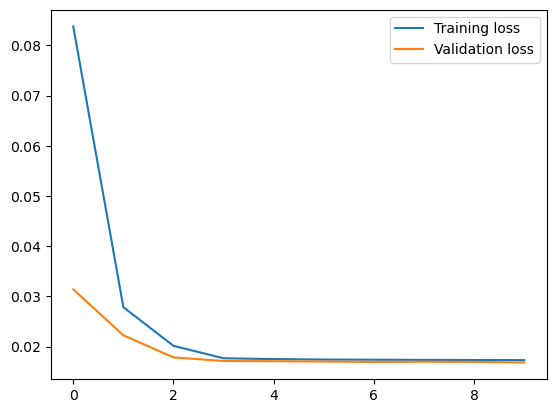

In [44]:
plt.plot(history.history["loss"],label="Training loss")
plt.plot(history.history["val_loss"],label="Validation loss")
plt.xlabel="Epochs"
plt.ylabel="loss"
plt.legend()
plt.show()

In [46]:
train_pred = model.predict(x_train)
train_error = np.mean(np.square(x_train-train_pred),axis=(1,2))
threshold = np.mean(train_error) +3* np.std(train_error)
print("Threshold:",threshold)

56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step
Threshold: 0.02439093454882516


In [49]:
test_pred = model.predict(x_test)
test_error = np.mean(np.square(x_test - test_pred),axis=(1,2))
y_pred = (test_error > threshold).astype(int)
print("Detected Anomalies:",np.sum(y_pred))

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
Detected Anomalies: 27


In [52]:
print("Confusion matrix")
print(confusion_matrix(y_test,y_pred))

print("Classification report")
print(classification_report(y_test,y_pred))

Confusion matrix
[[484   0]
 [485  27]]
Classification report
              precision    recall  f1-score   support

           0       0.50      1.00      0.67       484
           1       1.00      0.05      0.10       512

    accuracy                           0.51       996
   macro avg       0.75      0.53      0.38       996
weighted avg       0.76      0.51      0.38       996



In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
# from tensorflow.keras import models,layers
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import classification_report,confusion_matrix
from tensorflow.keras.layers import RepeatVector,LSTM,TimeDistributed,Dense

df = pd.read_csv("energy consumption.csv")
print(df.head())
print(df.shape)

df["Timestamp"] = pd.to_datetime(df["Timestamp"],dayfirst=True)
df = df.sort_values("Timestamp")

df = df.fillna(df.median(numeric_only=True))
x = df.drop(["Timestamp","Anomaly_Label"],axis=1)
y = df["Anomaly_Label"]


scaler = MinMaxScaler()
x = scaler.fit_transform(x)


window_size = 24

x_seq=[]
y_seq=[]

for i in range(len(x) - window_size+1):
    x_seq.append(x[i:i+window_size])
    y_seq.append(int(np.any(y.iloc[i:i+window_size])))
x_seq = np.array(x_seq)
y_seq = np.array(y_seq)

print(x_seq.shape)

split = int(0.8*len(x_seq))

x_train = x_seq[:split]
x_test = x_seq[split:]

y_test = y_seq[split:]

x_train = x_train[y_seq[:split]==0]

model = models.Sequential([
    layers.Input(shape=(24,5)),
    LSTM(32,activation="relu"),
    RepeatVector(24),
    LSTM(32,activation="relu",return_sequences=True),
    TimeDistributed(Dense(5))
])
model.summary()

model.compile(
    optimizer="adam",
    loss="mse"
)


history = model.fit(
    x_train,x_train,
    epochs=10,
    batch_size = 32,
    validation_split=0.1
)

plt.plot(history.history["loss"],label="Training loss")
plt.plot(history.history["val_loss"],label="Validation loss")
plt.xlabel="Epochs"
plt.ylabel="loss"
plt.legend()
plt.show()

train_pred = model.predict(x_train)
train_error = np.mean(np.square(x_train-train_pred),axis=(1,2))
threshold = np.mean(train_error) +3* np.std(train_error)
print("Threshold:",threshold)


test_pred = model.predict(x_test)
test_error = np.mean(np.square(x_test - test_pred),axis=(1,2))
y_pred = (test_error > threshold).astype(int)
print("Detected Anomalies:",np.sum(y_pred))

print("Confusion matrix")
print(confusion_matrix(y_test,y_pred))

print("Classification report")
print(classification_report(y_test,y_pred))

          Timestamp  Electricity_Consumed  Temperature  Humidity  Wind_Speed  \
0  01-01-2024 00:00              0.457786     0.469524  0.396368    0.445441   
1  01-01-2024 00:30              0.351956     0.465545  0.451184    0.458729   
2  01-01-2024 01:00              0.482948     0.285415  0.408289    0.470360   
3  01-01-2024 01:30              0.628838     0.482095  0.512308    0.576241   
4  01-01-2024 02:00              0.335974     0.624741  0.672021    0.373004   

   Avg_Past_Consumption  Anomaly_Label  
0              0.692057              0  
1              0.539874              0  
2              0.614724              0  
3              0.757044              0  
4              0.673981              0  
(5000, 7)
(4977, 24, 5)
